In [1]:
import numpy as np
import pandas as pd

# load tarining data
df = pd.read_csv('train/alphabet_dataset.txt', header=None)
data = df.values

# split features and labels
X = data[:, :63].astype(float)
labels = data[:, 63]

In [3]:
# labels matrix
Y = np.full((len(labels), 26), -1)
for i, char in enumerate(labels):
    idx = ord(char.upper()) - ord('A')
    Y[i, idx] = 1

In [5]:
# activation function bipolar sigmoid 
def sigmoid_act(x):
    x = np.asarray(x, dtype=float)
    x = np.clip(x, -60, 60)

    return (2.0 / (1.0 + np.exp(-x))) - 1.0

# derivative of activation function
def d_sigmoid(fx):
    return (0.5 * (1.0 - fx) * (1.0 + fx))

In [7]:
# matrix of initalize weights
def initialize_weights(in_units, hid_units, out_units):
    
    # weights matrix between input_layer and hidden_layer
    W1 = np.random.uniform(-0.5, 0.5, (in_units, hid_units))
    b1 = np.random.uniform(-0.5, 0.5, (1, hid_units)) # bias for hidden layer

    # weights matrix between hidden_layer and output_layer
    W2 = np.random.uniform(-0.5, 0.5, (hid_units, out_units))
    b2 = np.random.uniform(-0.5, 0.5, (1, out_units)) # bias for output layer
    
    return W1, b1, W2, b2

In [9]:
# backprop function
def backprop_step(X, Y, W1, b1, W2, b2, lr):

    # forward pass
    out_hidden = sigmoid_act(X @ W1 + b1)
    out_output = sigmoid_act(out_hidden @ W2 + b2)

    # backward pass
    error_diff = Y - out_output
    d_output = error_diff * d_sigmoid(out_output)
    d_hidden = (d_output @ W2.T) * d_sigmoid(out_hidden)

    # update (batch gradient descent)
    N = X.shape[0]   # number of training samples
    
    W2 += (lr / N) * (out_hidden.T @ d_output)
    b2 += (lr / N) * np.sum(d_output, axis=0, keepdims=True)
    
    W1 += (lr / N) * (X.T @ d_hidden)
    b1 += (lr / N) * np.sum(d_hidden, axis=0, keepdims=True)

    return W1, b1, W2, b2, out_output

## Train MLP by defferent parameters

In [12]:
# problem's constants----------------------------------------
input_units = 63
hidden_units = [10, 15, 20, 25, 30]
output_units = 26
lrs_list = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
epochs_list = [100, 200, 300, 400, 500, 600, 700, 800, 900, 1000]
# -----------------------------------------------------------

epc_targets = set(epochs_list) 
epoch_to_col = {e: j for j, e in enumerate(epochs_list)}
max_epoch = max(epochs_list)

# create matrix for saving results: (hidden, lr, epoch_milestone)
results_mse = np.zeros((len(hidden_units), len(lrs_list), len(epochs_list)))

for h_idx, h in enumerate(hidden_units):
    for lr_idx, lr in enumerate(lrs_list):

        # fixed init for fair lr comparison 
        np.random.seed(123)
        W1, b1, W2, b2 = initialize_weights(input_units, h, output_units)

        for epc in range(1, max_epoch + 1):
            W1, b1, W2, b2, out_output = backprop_step(X, Y, W1, b1, W2, b2, lr)

            # save snapshot in epc_targets
            if epc in epc_targets:
                mse = np.mean((Y - out_output) ** 2)
                e_idx = epoch_to_col[epc]
                results_mse[h_idx, lr_idx, e_idx] = mse

In [14]:
# create table for results of each hidden layers units' value
def table_for_hidden(results_mse, hidden_units, h_value, lrs_list, epochs_list):
    h_idx = hidden_units.index(h_value)
    df_table = pd.DataFrame(
        results_mse[h_idx, :, :],
        index=[f"lr={lr}" for lr in lrs_list],
        columns=[f"ep={e}" for e in epochs_list]
    )
    df_table.index.name = f"Hidden={h_value}"
    return df_table

In [16]:
# draw tables
for h in hidden_units:
    print("\n", "="*60)
    print(f"Hidden Units = {h}")
    display(table_for_hidden(results_mse, hidden_units, h, lrs_list, epochs_list))



Hidden Units = 10


,ep=100,ep=200,ep=300,ep=400,ep=500,ep=600,ep=700,ep=800,ep=900,ep=1000
Hidden=10,,,,,,,,,,
lr=0.1,0.146956,0.141368,0.136649,0.131099,0.124929,0.118475,0.111480,0.104329,0.097855,0.091537
lr=0.2,0.141057,0.130162,0.117188,0.103022,0.090765,0.080059,0.071416,0.064235,0.058158,0.052977
lr=0.3,0.135329,0.115797,0.096406,0.079663,0.066983,0.057919,0.050640,0.043079,0.036055,0.029896
lr=0.4,0.128402,0.101796,0.079547,0.063059,0.052777,0.042922,0.034182,0.026367,0.020349,0.016752
lr=0.5,0.120772,0.090456,0.066089,0.052317,0.040067,0.030230,0.021922,0.016416,0.011871,0.008786
lr=0.6,0.113511,0.080142,0.057069,0.041627,0.029200,0.020065,0.015149,0.010638,0.007597,0.006019
lr=0.7,0.107026,0.070937,0.049466,0.033077,0.020809,0.014867,0.009502,0.006758,0.005330,0.004417
lr=0.8,0.102173,0.064828,0.042495,0.026607,0.017084,0.012869,0.009272,0.006120,0.004650,0.003797
lr=0.9,0.098036,0.061379,0.035817,0.021299,0.014166,0.010895,0.006963,0.004775,0.003754,0.003122



Hidden Units = 15


,ep=100,ep=200,ep=300,ep=400,ep=500,ep=600,ep=700,ep=800,ep=900,ep=1000
Hidden=15,,,,,,,,,,
lr=0.1,0.141288,0.130587,0.119700,0.107902,0.096626,0.086676,0.077776,0.069321,0.061729,0.054530
lr=0.2,0.130675,0.107944,0.086816,0.069224,0.053842,0.041112,0.033384,0.027024,0.021563,0.018065
lr=0.3,0.119831,0.086977,0.061085,0.040685,0.029850,0.021260,0.016657,0.014080,0.012090,0.008526
lr=0.4,0.108202,0.069510,0.040604,0.026093,0.017732,0.014016,0.010247,0.006078,0.004518,0.003629
lr=0.5,0.097700,0.054406,0.028931,0.017636,0.012945,0.006865,0.004716,0.003602,0.002840,0.002372
lr=0.6,0.089635,0.042968,0.020877,0.011974,0.006434,0.004420,0.003361,0.002707,0.002262,0.001938
lr=0.7,0.083260,0.035027,0.017002,0.008078,0.005044,0.003579,0.002748,0.002224,0.001865,0.001605
lr=0.8,0.077547,0.030158,0.012002,0.006587,0.004172,0.003014,0.002353,0.001926,0.001627,0.001407
lr=0.9,0.073100,0.026495,0.009843,0.005599,0.003523,0.002563,0.002012,0.001654,0.001403,0.001217



Hidden Units = 20


,ep=100,ep=200,ep=300,ep=400,ep=500,ep=600,ep=700,ep=800,ep=900,ep=1000
Hidden=20,,,,,,,,,,
lr=0.1,0.132752,0.110826,0.091712,0.078794,0.067538,0.055705,0.046006,0.038244,0.032827,0.028814
lr=0.2,0.110628,0.078480,0.054631,0.037491,0.028519,0.022002,0.015032,0.011490,0.008690,0.006171
lr=0.3,0.091226,0.053826,0.032033,0.021707,0.013174,0.008199,0.005493,0.004278,0.003500,0.002956
lr=0.4,0.077982,0.036673,0.021482,0.010945,0.005977,0.004235,0.003272,0.002657,0.002230,0.001917
lr=0.5,0.065170,0.028039,0.012779,0.005880,0.003914,0.002914,0.002310,0.001907,0.001619,0.001404
lr=0.6,0.053212,0.022103,0.007215,0.004183,0.002909,0.002214,0.001778,0.001482,0.001267,0.001105
lr=0.7,0.045132,0.014555,0.005357,0.003272,0.002326,0.001791,0.001450,0.001215,0.001044,0.000913
lr=0.8,0.040106,0.010235,0.004354,0.002720,0.001956,0.001518,0.001235,0.001038,0.000893,0.000783
lr=0.9,0.036822,0.008508,0.003753,0.002370,0.001713,0.001333,0.001087,0.000915,0.000789,0.000692



Hidden Units = 25


,ep=100,ep=200,ep=300,ep=400,ep=500,ep=600,ep=700,ep=800,ep=900,ep=1000
Hidden=25,,,,,,,,,,
lr=0.1,0.125274,0.096810,0.077314,0.065016,0.055661,0.046858,0.037776,0.031072,0.025605,0.021742
lr=0.2,0.097028,0.064898,0.046241,0.030821,0.021523,0.015596,0.010851,0.007929,0.006125,0.004949
lr=0.3,0.077621,0.045660,0.025356,0.014191,0.008698,0.005929,0.004408,0.003477,0.002855,0.002414
lr=0.4,0.065032,0.030239,0.013367,0.007387,0.004767,0.003450,0.002678,0.002176,0.001826,0.001569
lr=0.5,0.055032,0.018701,0.008238,0.004711,0.003194,0.002386,0.001891,0.001560,0.001323,0.001147
lr=0.6,0.046097,0.012597,0.005687,0.003398,0.002373,0.001806,0.001449,0.001206,0.001030,0.000898
lr=0.7,0.038548,0.009342,0.004301,0.002658,0.001892,0.001457,0.001179,0.000987,0.000847,0.000741
lr=0.8,0.035119,0.007426,0.003494,0.002206,0.001591,0.001236,0.001005,0.000845,0.000727,0.000637
lr=0.9,0.031700,0.006311,0.002987,0.001901,0.001378,0.001074,0.000876,0.000737,0.000635,0.000557



Hidden Units = 30


,ep=100,ep=200,ep=300,ep=400,ep=500,ep=600,ep=700,ep=800,ep=900,ep=1000
Hidden=30,,,,,,,,,,
lr=0.1,0.128684,0.100336,0.076647,0.058918,0.043498,0.032889,0.025899,0.020073,0.015761,0.012699
lr=0.2,0.100104,0.058455,0.032609,0.019689,0.012585,0.009349,0.007567,0.006443,0.005676,0.005121
lr=0.3,0.076099,0.032325,0.015439,0.009292,0.006918,0.005657,0.004886,0.004370,0.004002,0.003729
lr=0.4,0.057881,0.019012,0.009237,0.006394,0.005093,0.004361,0.003897,0.003578,0.003346,0.003171
lr=0.5,0.042708,0.012341,0.006865,0.005081,0.004219,0.003719,0.003394,0.003168,0.003002,0.002875
lr=0.6,0.031779,0.009179,0.005613,0.004346,0.003713,0.003338,0.003091,0.002918,0.002789,0.002690
lr=0.7,0.024194,0.007467,0.004856,0.003884,0.003387,0.003089,0.002891,0.002751,0.002647,0.002567
lr=0.8,0.019317,0.006419,0.004364,0.003576,0.003167,0.002920,0.002754,0.002637,0.002549,0.002481
lr=0.9,0.016376,0.005734,0.004026,0.003360,0.003011,0.002799,0.002656,0.002554,0.002478,0.002419


In [18]:
# Best parameters and min cost (MSE)

best_flat_idx = np.argmin(results_mse)  # index in flattened array
h_idx, lr_idx, e_idx = np.unravel_index(best_flat_idx, results_mse.shape)

best_hidden = hidden_units[h_idx]
best_lr = lrs_list[lr_idx]
best_epoch = epochs_list[e_idx]
best_mse = results_mse[h_idx, lr_idx, e_idx]

print("Best (GLOBAL) hyperparameters:")
print("Hidden Units =", best_hidden)
print("Learning Rate =", best_lr)
print("Epoch =", best_epoch)
print("Min Train MSE =", best_mse)


Best (GLOBAL) hyperparameters:
Hidden Units = 25
Learning Rate = 0.9
Epoch = 1000
Min Train MSE = 0.0005573604812688512


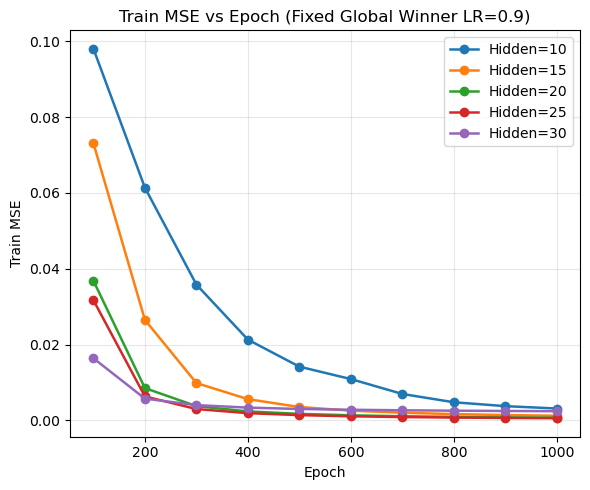

In [20]:
# Plot MSE vs Epoch (fixed lerning rate = lr winner)
import matplotlib.pyplot as plt
import numpy as np

hidden_units = [10, 15, 20, 25, 30]
lrs_list = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
epochs_list = [100, 200, 300, 400, 500, 600, 700, 800, 900, 1000]

e_final = 1000
e_final_idx = epochs_list.index(e_final)

# best learning rate at epoch=1000
slice_1000 = results_mse[:, :, e_final_idx]  # shape: (hidden, lr)

best_flat_idx = int(np.argmin(slice_1000))
best_h_idx, best_lr_idx = np.unravel_index(best_flat_idx, slice_1000.shape)

lr_winner = lrs_list[best_lr_idx]
best_mse_1000 = slice_1000[best_h_idx, best_lr_idx]


# train MSE vs Epoch for all hidden units, fixed LR = lr_winner
plt.figure(figsize=(6, 5))

for h_idx, h in enumerate(hidden_units):
    y = results_mse[h_idx, best_lr_idx, :]  # MSE vs epochs at fixed global-winner lr
    plt.plot(epochs_list, y, marker='o', linewidth=1.8, label=f"Hidden={h}")

plt.xlabel("Epoch")
plt.ylabel("Train MSE")
plt.title(f"Train MSE vs Epoch (Fixed Global Winner LR={lr_winner})")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


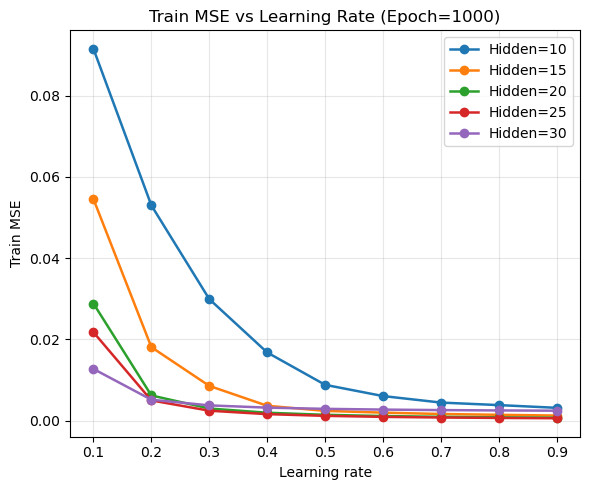

In [22]:
# plot MSE vs Learnin Rate (fixed epoch = final epoch)
import matplotlib.pyplot as plt
import numpy as np

hidden_units = [10, 15, 20, 25, 30]
lrs_list = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
epochs_list = [100, 200, 300, 400, 500, 600, 700, 800, 900, 1000]

e_final = 1000
e_final_idx = epochs_list.index(e_final)

plt.figure(figsize=(6, 5))

for h_idx, h in enumerate(hidden_units):
    # MSE vs LR at fixed epoch = 1000
    y = results_mse[h_idx, :, e_final_idx]
    plt.plot(lrs_list, y, marker='o', linewidth=1.8, label=f"Hidden={h}")

plt.xlabel("Learning rate")
plt.ylabel("Train MSE")
plt.title(f"Train MSE vs Learning Rate (Epoch={e_final})")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [24]:
# FINAL TRAINING

# fixed hyperparameters ----------
input_units = 63
output_units = 26
H_BEST = best_hidden
LR_BEST = best_lr
EPOCHS_BEST = best_epoch
# --------------------------------

np.random.seed(123)

# initialize weights
W1, b1, W2, b2 = initialize_weights(input_units, H_BEST, output_units)

# training loop
for epc in range(EPOCHS_BEST):
    W1, b1, W2, b2, out_output = backprop_step(
        X, Y,
        W1, b1, W2, b2,
        LR_BEST
    )

# saving optimal weights
np.savez(
    "final_trained_model.npz",
    W1=W1,
    b1=b1,
    W2=W2,
    b2=b2,
    hidden_units=H_BEST,
    learning_rate=LR_BEST,
    epochs=EPOCHS_BEST
)


In [26]:
# forward pass on train
out_hidden_tr = sigmoid_act(X @ W1 + b1)
out_output_tr = sigmoid_act(out_hidden_tr @ W2 + b2)

# train accuracy 
acc_train = np.mean(
    np.argmax(out_output_tr, axis=1) == np.argmax(Y, axis=1)
)

print("Train Accuracy =", acc_train)

# predicted classes
pred_tr = np.argmax(out_output_tr, axis=1)
print("Train unique predicted classes:", np.unique(pred_tr))


Train Accuracy = 1.0
Train unique predicted classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25]


In [28]:
# evaluate test sets on optimal parameters

import pandas as pd
import numpy as np

# load trained weights
ckpt = np.load("final_trained_model.npz")
W1 = ckpt["W1"]
b1 = ckpt["b1"]
W2 = ckpt["W2"]
b2 = ckpt["b2"]

# test datasets paths
test_sets = {
    "Test 10%": "test/letter10error.txt",
    "Test 15%": "test/letter15error.txt",
    "Test 20%": "test/letter20error.txt",
}

results = []

# evaluation loop
for name, path in test_sets.items():

    # load test file
    df = pd.read_csv(path, header=None)
    data = df.values

    X_test = data[:, :63].astype(float)
    labels = data[:, 63]

    # convert label to bipolar
    Y_test = np.full((len(labels), 26), -1.0)
    for i, char in enumerate(labels):
        idx = ord(str(char).upper()) - ord('A')
        Y_test[i, idx] = 1.0

    # forward pass 
    out_hidden = sigmoid_act(X_test @ W1 + b1)
    out_output = sigmoid_act(out_hidden @ W2 + b2)

    # metrics 
    mse = np.mean((Y_test - out_output) ** 2)
    correct = np.sum(
    np.argmax(out_output, axis=1) == np.argmax(Y_test, axis=1))
    acc = correct / len(Y_test)

    results.append([name, mse, acc])

# results table
results_df = pd.DataFrame(
    results,
    columns=["Dataset", "MSE", "Accuracy"]
).set_index("Dataset")

results_df


,MSE,Accuracy
Dataset,,
Test 10%,0.106442,0.615385
Test 15%,0.175274,0.615385
Test 20%,0.179669,0.500000


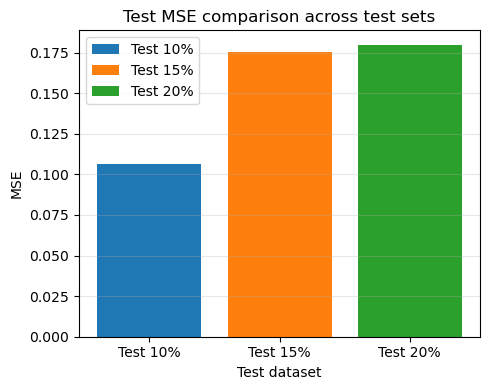

In [30]:
# Diagram to compare MSE at test sets

import matplotlib.pyplot as plt
import numpy as np

datasets = results_df.index.tolist()
mse_vals = results_df["MSE"].values

x = np.arange(len(datasets))
colors = ["tab:blue", "tab:orange", "tab:green"]

plt.figure(figsize=(5, 4))
plt.bar(x, mse_vals, color=colors)

plt.xticks(x, datasets)
plt.xlabel("Test dataset")
plt.ylabel("MSE")
plt.title("Test MSE comparison across test sets")
plt.grid(True, axis="y", alpha=0.3)

# legend
for i, name in enumerate(datasets):
    plt.bar(0, 0, color=colors[i], label=name)
plt.legend()

plt.tight_layout()
plt.show()


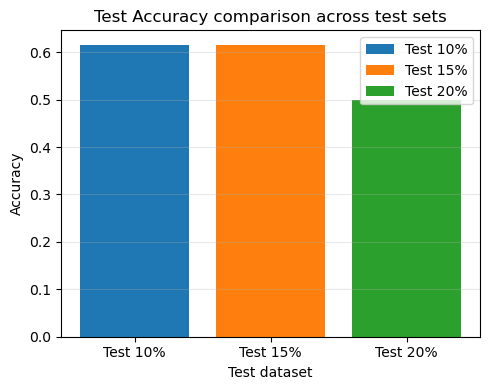

In [32]:
# Diagram to compare Accuracy at test sets

acc_vals = results_df["Accuracy"].values

plt.figure(figsize=(5, 4))
plt.bar(x, acc_vals, color=colors)

plt.xticks(x, datasets)
plt.xlabel("Test dataset")
plt.ylabel("Accuracy")
plt.title("Test Accuracy comparison across test sets")
plt.grid(True, axis="y", alpha=0.3)

for i, name in enumerate(datasets):
    plt.bar(0, 0, color=colors[i], label=name)
plt.legend()

plt.tight_layout()
plt.show()
